In [3]:
'''
In this section, we imported the necessary libraries that we choose to use for this
project. We are using pandas for data handling, numpy for numerical & operations,
sklearn for preprocessing & evaluatoin, and tensorflow/keras for building the 
ids-ai model.
'''
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.ensemble import RandomForestClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers # added to support layers.Input
from tensorflow.keras.layers import Dense

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


In [8]:
# Here we are loading the dataset that we created for this project.
# We load a preview of the data to ensure we are working with the correct file. 
ds = pd.read_csv('~//anaconda3/merged_dataset.csv')

print('\n--- Head (First 5 Rows) ---')
display(ds.head())
print('\n--- Column Information (Data Types, Non-Null Counts) ---')
ds.info()


--- Head (First 5 Rows) ---


,session_id,login_attempts,session_duration,ip_reputation_score,failed_logins,attack_detected
0,SID_00031,1,447.623307,0.099390,0,0
1,SID_00556,1,112.956851,0.329503,0,0
2,SID_00646,1,155.660698,0.448157,0,1
3,SID_00705,1,1791.705933,0.556327,0,0
4,SID_00713,1,1675.976772,0.489591,0,0



--- Column Information (Data Types, Non-Null Counts) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10645 entries, 0 to 10644
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           10645 non-null  object 
 1   login_attempts       10645 non-null  int64  
 2   session_duration     10645 non-null  float64
 3   ip_reputation_score  10645 non-null  float64
 4   failed_logins        10645 non-null  int64  
 5   attack_detected      10645 non-null  int64  
dtypes: float64(2), int64(3), object(1)
memory usage: 499.1+ KB


In [26]:
'''
In this section, we prepare the data for modeling by separating the features
and the target, as well as encoding categorial variables, and scaling 
numerical features from the data. 
'''

# Separate features and target variable

X = ds.drop(labels=['session_id', 'attack_detected'], axis=1)
y = ds['attack_detected']

# Display the selected features
print("\n--- Selected Features ---")
print(X.head())

print("\n--- Target Variable ---")
print(y.head())

print("\n--- Dataset After Preprocessing ---")
print(X.head())


--- Selected Features ---
   login_attempts  session_duration  ip_reputation_score  failed_logins
0               1        447.623307             0.099390              0
1               1        112.956851             0.329503              0
2               1        155.660698             0.448157              0
3               1       1791.705933             0.556327              0
4               1       1675.976772             0.489591              0

--- Target Variable ---
0    0
1    0
2    1
3    0
4    0
Name: attack_detected, dtype: int64

--- Dataset After Preprocessing ---
   login_attempts  session_duration  ip_reputation_score  failed_logins
0               1        447.623307             0.099390              0
1               1        112.956851             0.329503              0
2               1        155.660698             0.448157              0
3               1       1791.705933             0.556327              0
4               1       1675.976772             

In [32]:
'''
After preparing the data, we now need to split the data into Train/Validation/Test.
We also need to fit the standard scaler to the training data individually. 

This will keep an 80/10/10 split while avoiding data leakage from fitting the scaler
on the entire dataset. 
'''

# Split into training, validation, and testing sets
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

# Split training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=(0.1 / 0.9),
    random_state=42,
    stratify=y_train_val
)

# Display dataset split sizes and percentages

print(f"Total dataset size: {ds.shape[0]}")

print(f"Training set size: {X_train.shape[0]} "
      f"({X_train.shape[0]/ds.shape[0]*100:.1f}%)")

print(f"Validation set size: {X_val.shape[0]} "
      f"({X_val.shape[0]/ds.shape[0]*100:.1f}%)")

print(f"Testing set size: {X_test.shape[0]} "
      f"({X_test.shape[0]/ds.shape[0]*100:.1f}%)")

# Standardize numerical features

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


Total dataset size: 10645
Training set size: 8515 (80.0%)
Validation set size: 1065 (10.0%)
Testing set size: 1065 (10.0%)


In [45]:
'''
Baseline ANN model
- 64 neurons in the first hidden layer
- 36 neurons in the second hidden layer
- 16 neurons in the third hidden layer
- 1 output neuron
'''


# Baseline ANN Model

input_features = X_train.shape[1] # automatically detects the number of input columns

model = Sequential()

model.add(tf.keras.Input(shape=(input_features,)))

model.add(Dense(64, activation='relu'))
model.add(Dense(36, activation='relu'))
model.add(Dense(16, activation='relu'))

# Binary classification output
model.add(Dense(1, activation='sigmoid'))

print("\n--- Baseline ANN Model Summary ---")
model.summary()

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)


--- Baseline ANN Model Summary ---
Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_41 (Dense)            (None, 64)                320       
                                                                 
 dense_42 (Dense)            (None, 36)                2340      
                                                                 
 dense_43 (Dense)            (None, 16)                592       
                                                                 
 dense_44 (Dense)            (None, 1)                 17        
                                                                 
Total params: 3,269
Trainable params: 3,269
Non-trainable params: 0
_________________________________________________________________
Epoch 1/10
267/267 [==============================] - 2s 3ms/step - loss: 0.5687 - accuracy: 0.6972 - val_loss: 0.5078 - val_accuracy: 0.7333
Epoch

In [46]:
'''
Here, we are doing a comparison model using Random Forest Classifier (RFT).
We are using this to serve as a benchmark against the deep learning model. 
'''

# Random Forest Classifier

# Initiralizes and trains the RF model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced' # to even out our dataset since our dataset contains an unevan number of attacks and normal sessions
)

rf_model.fit(X_train, y_train)

# Makes predictions and evaluates
rf_y_pred = rf_model.predict(X_test)
print("\n--- Random Forest Classification Report ---")
print(classification_report(
    y_test,
    rf_y_pred,
    zero_division=0
))



--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.81      0.97      0.88       528
           1       0.96      0.78      0.86       537

    accuracy                           0.87      1065
   macro avg       0.88      0.87      0.87      1065
weighted avg       0.89      0.87      0.87      1065



In [47]:
'''
Second ANN model using different hyperparameters which were "sgd" optimizer, only 
two hidden layers. 
'''
# Experimental ANN Model

model_exp = Sequential()

model_exp.add(tf.keras.Input(shape=(input_features,)))

model_exp.add(Dense(32, activation='relu'))
model_exp.add(Dense(16, activation='relu'))

model_exp.add(Dense(1, activation='sigmoid'))

# Compile with SGD optimizer
model_exp.compile(
    optimizer='sgd', # Different optimizer
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train for 5 epochs
history_exp = model_exp.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

# Evaluation and Visualization
test_loss_exp, test_acc_exp = model_exp.evaluate(
    X_test, y_test, verbose=0
)

print(
    f"Experimental ANN Test Accuracy (SGD, 2 Layers, 5 epochs): {test_acc_exp:.4f}"
)

Epoch 1/5
267/267 [==============================] - 2s 3ms/step - loss: 0.6660 - accuracy: 0.6127 - val_loss: 0.6530 - val_accuracy: 0.6516
Epoch 2/5
267/267 [==============================] - 0s 2ms/step - loss: 0.6428 - accuracy: 0.6559 - val_loss: 0.6387 - val_accuracy: 0.6676
Epoch 3/5
267/267 [==============================] - 0s 1ms/step - loss: 0.6293 - accuracy: 0.6654 - val_loss: 0.6266 - val_accuracy: 0.6563
Epoch 4/5
267/267 [==============================] - 0s 1ms/step - loss: 0.6173 - accuracy: 0.6693 - val_loss: 0.6157 - val_accuracy: 0.6667
Epoch 5/5
267/267 [==============================] - 0s 1ms/step - loss: 0.6062 - accuracy: 0.6786 - val_loss: 0.6055 - val_accuracy: 0.6648
Experimental ANN Test Accuracy (SGD, 2 Layers, 5 epochs): 0.6601


In [48]:
'''
We then do model evaluation and visualation of our second ANN.
'''

# Evaluate baseline ANN

test_loss, test_acc = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Baseline ANN Test Accuracy: {test_acc:.4f}")

# Generate predictions
ann_y_prob = model.predict(X_test)

ann_y_pred = (ann_y_prob > 0.5).astype("int32")

# Classification report
print("\n--- Baseline ANN Classification Report ---")

print(classification_report(
    y_test,
    ann_y_pred,
    zero_division=0
))


Baseline ANN Test Accuracy: 0.8620
34/34 [==============================] - 0s 1ms/step

--- Baseline ANN Classification Report ---
              precision    recall  f1-score   support

           0       0.79      0.98      0.88       528
           1       0.98      0.74      0.84       537

    accuracy                           0.86      1065
   macro avg       0.88      0.86      0.86      1065
weighted avg       0.88      0.86      0.86      1065



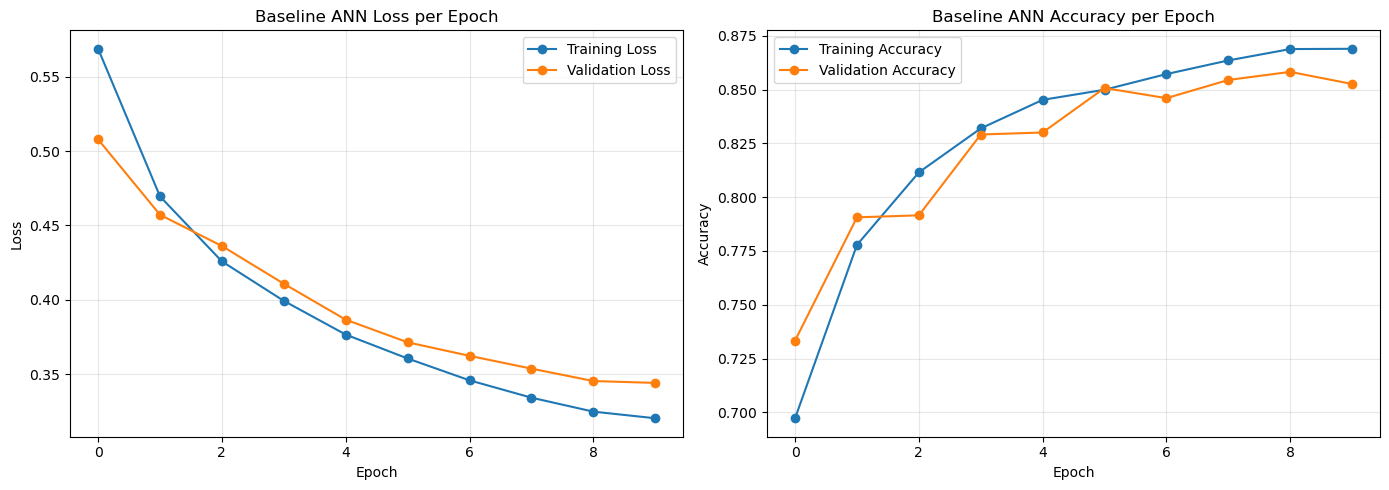

In [49]:

# ==========================================
# ANN TRAINING HISTORY VISUALIZATION
# ==========================================
'''
This visualization shows how the ANN learns over the training epochs and whether
it is overfitting (ANN training history aka loss & accuracy)
'''

plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'],
         label='Training Loss',
         marker='o')

plt.plot(history.history['val_loss'],
         label='Validation Loss',
         marker='o')

plt.title('Baseline ANN Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot Accuracy
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'],
         label='Training Accuracy',
         marker='o')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy',
         marker='o')

plt.title('Baseline ANN Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig('ann_training_history.png', dpi=300)

plt.show()

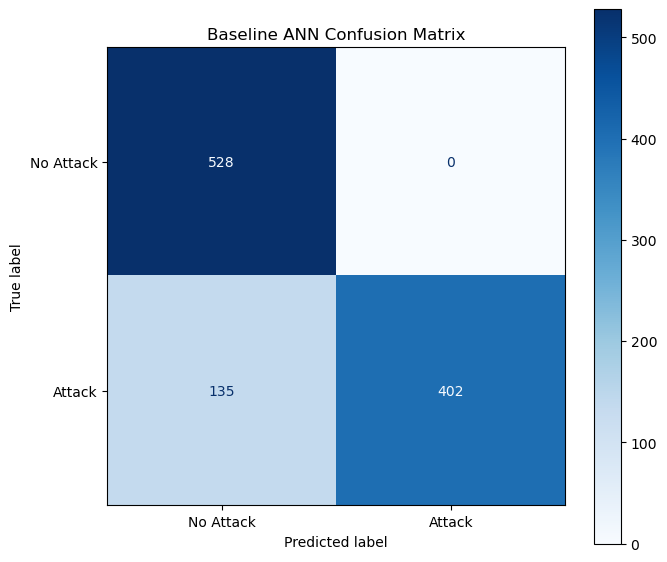

In [22]:

# ==========================================
# ANN CONFUSION MATRIX
# ==========================================

'''
Baseline ANN Confusion Matrix
Shows how the IDS model correctly identifies how many attacks and how many it misses
'''

ann_cm = confusion_matrix(y_test, ann_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=ann_cm,
    display_labels=["No Attack", "Attack"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap=plt.cm.Blues,
    values_format='d',
    ax=ax
)

plt.title('Baseline ANN Confusion Matrix')
plt.tight_layout()

plt.savefig('ann_confusion_matrix.png', dpi=300)

plt.show()


Class Weights: {0: 1.0093646277856805, 1: 0.9908075401442867}


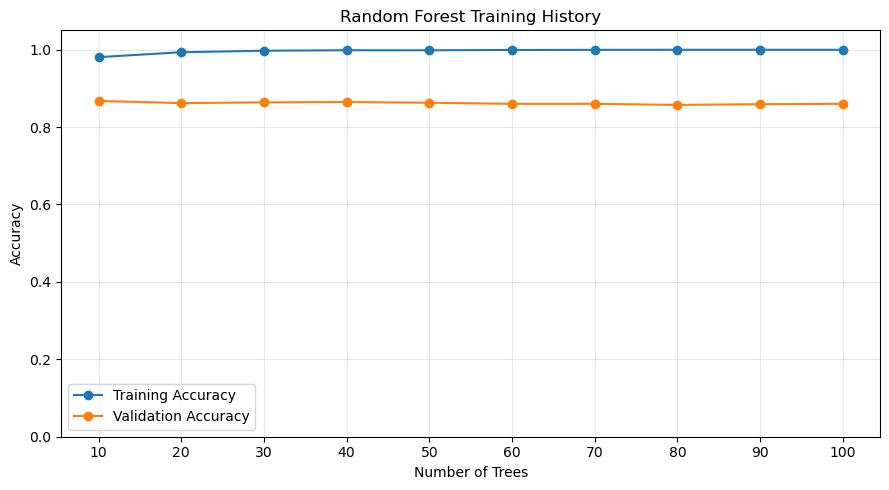

In [50]:

# ==========================================
# RANDOM FOREST TRAINING HISTORY
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights manually
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

# Number of trees to evaluate
n_trees = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

train_accuracies = []
val_accuracies = []

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=10,
    random_state=42,
    warm_start=True,
    class_weight=class_weights
)

# Train incrementally
for n in n_trees:

    rf_model.set_params(n_estimators=n)

    rf_model.fit(X_train, y_train)

    # Training accuracy
    train_pred = rf_model.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)
    train_accuracies.append(train_acc)

    # Validation accuracy
    val_pred = rf_model.predict(X_val)
    val_acc = accuracy_score(y_val, val_pred)
    val_accuracies.append(val_acc)

# ==========================================
# VISUALIZE TRAINING HISTORY
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    n_trees,
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    n_trees,
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.title('Random Forest Training History')
plt.xlabel('Number of Trees')
plt.ylabel('Accuracy')

plt.xticks(n_trees)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig('rf_training_history.png', dpi=300)

plt.show()


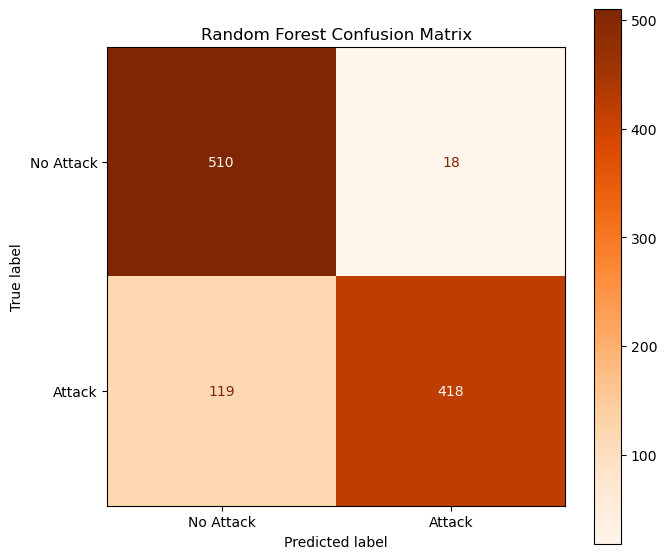

In [38]:

# ==========================================
# RANDOM FOREST CONFUSION MATRIX
# ==========================================

rf_cm = confusion_matrix(y_test, rf_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Attack", "Attack"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap=plt.cm.Oranges,
    values_format='d',
    ax=ax
)

plt.title('Random Forest Confusion Matrix')
plt.tight_layout()

plt.savefig('rf_confusion_matrix.png', dpi=300)

plt.show()


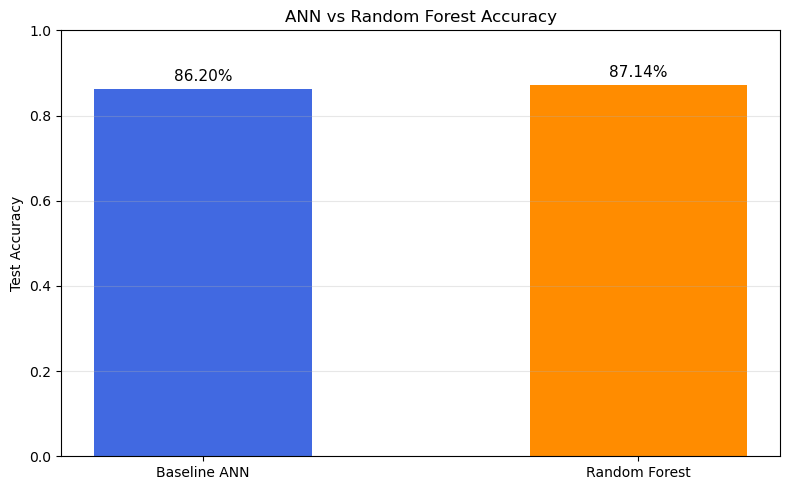

In [51]:

# ==========================================
# MODEL ACCURACY COMPARISON
# ==========================================

'''
Compares the precision, recall, and F1-scores for the attack class across both models
'''

rf_accuracy = rf_model.score(X_test, y_test)

ann_accuracy = test_acc

models = ['Baseline ANN', 'Random Forest']
accuracies = [ann_accuracy, rf_accuracy]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies,
    color=['royalblue', 'darkorange'],
    width=0.5
)

plt.title('ANN vs Random Forest Accuracy')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)

# Display accuracy percentages above bars
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f'{accuracy:.2%}',
        ha='center',
        fontsize=11
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig('model_accuracy_comparison.png', dpi=300)

plt.show()


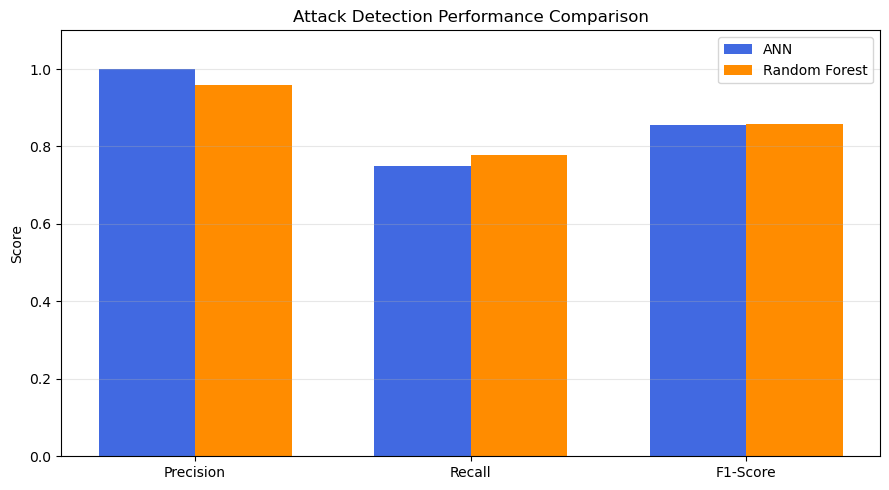

In [25]:

# ==========================================
# ATTACK DETECTION PERFORMANCE
# ==========================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate metrics for ANN
ann_precision = precision_score(y_test, ann_y_pred, zero_division=0)
ann_recall = recall_score(y_test, ann_y_pred, zero_division=0)
ann_f1 = f1_score(y_test, ann_y_pred, zero_division=0)

# Calculate metrics for Random Forest
rf_precision = precision_score(y_test, rf_y_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_y_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_y_pred, zero_division=0)

# Organize results
metrics = ['Precision', 'Recall', 'F1-Score']

ann_scores = [ann_precision, ann_recall, ann_f1]
rf_scores = [rf_precision, rf_recall, rf_f1]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    ann_scores,
    width,
    label='ANN',
    color='royalblue'
)

plt.bar(
    x + width/2,
    rf_scores,
    width,
    label='Random Forest',
    color='darkorange'
)

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.title('Attack Detection Performance Comparison')
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig('attack_detection_comparison.png', dpi=300)

plt.show()
